# 06 — Avaliação, comparação e interpretação

Resultados no **teste de 2025**, usado uma única vez por modelo e cenário depois de todas as escolhas feitas na validação. Tabelas e figuras são geradas por `python -m src.evaluate`.

In [1]:
# Configuração: roda a partir da raiz do repositório
import os, sys, warnings
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
from src import config

In [2]:
GERAR = False  # True para regenerar tabelas e figuras (~5 min)
from src import evaluate as ev
if GERAR:
    ev.gerar_relatorio()
res = pd.read_csv(config.TABLES_DIR / "resultados_teste_2025.csv")
ordem = {"dummy": 0, "lr": 1, "rf": 2, "xgb": 3}
cols = ["modelo", "cenario", "f1_macro", "f1_macro_ic_inf", "f1_macro_ic_sup", "f1_macro_argmax", "recall_fatais", "precision_fatais",
        "f1_fatais", "pr_auc_fatais", "roc_auc_macro_ovr", "acuracia", "brier_medio"]
res.assign(o=res.modelo.map(ordem)).sort_values(["cenario", "o"])[cols].round(3)

,modelo,cenario,f1_macro,f1_macro_ic_inf,f1_macro_ic_sup,f1_macro_argmax,recall_fatais,precision_fatais,f1_fatais,pr_auc_fatais,roc_auc_macro_ovr,acuracia,brier_medio
0,dummy,A,0.334,NaN,NaN,0.334,0.072,0.073,0.072,0.072,0.500,0.618,0.124
2,lr,A,0.543,0.537,0.547,0.459,0.382,0.375,0.378,0.316,0.768,0.747,0.103
4,rf,A,0.551,0.546,0.556,0.508,0.407,0.381,0.394,0.328,0.771,0.744,0.163
6,xgb,A,0.561,0.555,0.566,0.485,0.421,0.391,0.405,0.348,0.780,0.759,0.173
7,xgb,A_pessoas,0.575,0.570,0.580,0.498,0.429,0.393,0.410,0.349,0.793,0.765,0.170
1,dummy,B,0.334,NaN,NaN,0.334,0.072,0.073,0.072,0.072,0.500,0.618,0.124
3,lr,B,0.436,0.431,0.440,0.306,0.256,0.223,0.238,0.179,0.664,0.674,0.118
5,rf,B,0.435,0.431,0.440,0.412,0.265,0.215,0.237,0.178,0.661,0.672,0.183
8,xgb,B,0.442,0.438,0.447,0.394,0.290,0.219,0.250,0.189,0.667,0.654,0.196
9,xgb,C,0.576,0.571,0.581,0.506,0.433,0.402,0.417,0.368,0.794,0.762,0.168


## 1. Comparação entre modelos e cenários

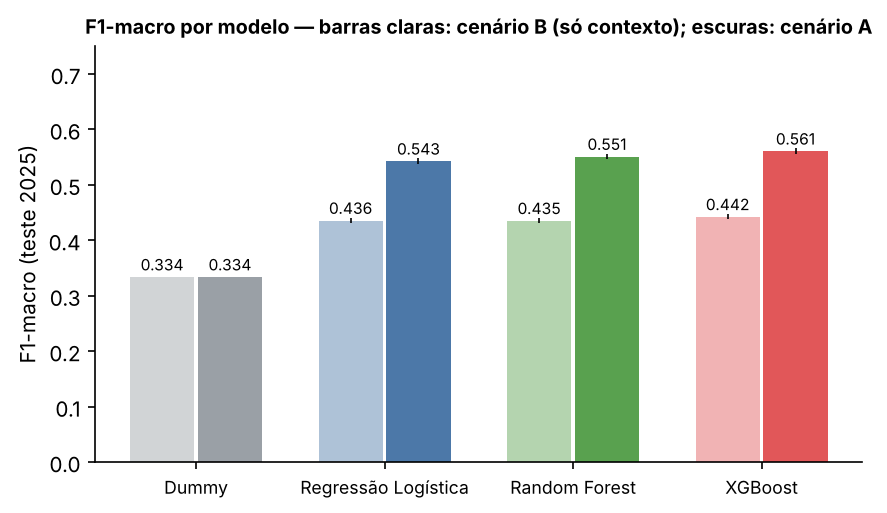

{'melhor_validacao': 'xgb_A',
 'segundo': 'rf_A',
 'mcnemar_melhor_vs_segundo': {'tabela': [[52012, 3031], [1924, 15561]],
  'estatistica': 246.86902119071644,
  'p_valor': 1.2503689917731911e-55},
 'mcnemar_melhor_vs_lr': {'tabela': [[51343, 3700], [2851, 14634]],
  'estatistica': 109.77011143336895,
  'p_valor': 1.1004012442531669e-25},
 'f1_validacao': {'lr_A': 0.5430203607290066,
  'rf_A': 0.5530720598178543,
  'xgb_A': 0.5610827130342236}}

In [3]:
display(Image(str(config.FIGURES_DIR / "res_04_f1_modelos_cenarios.png")))
comp = json.loads((config.TABLES_DIR / "comparacao_estatistica.json").read_text())
comp

## 2. Classe Fatais: curva precisão-recall e calibração

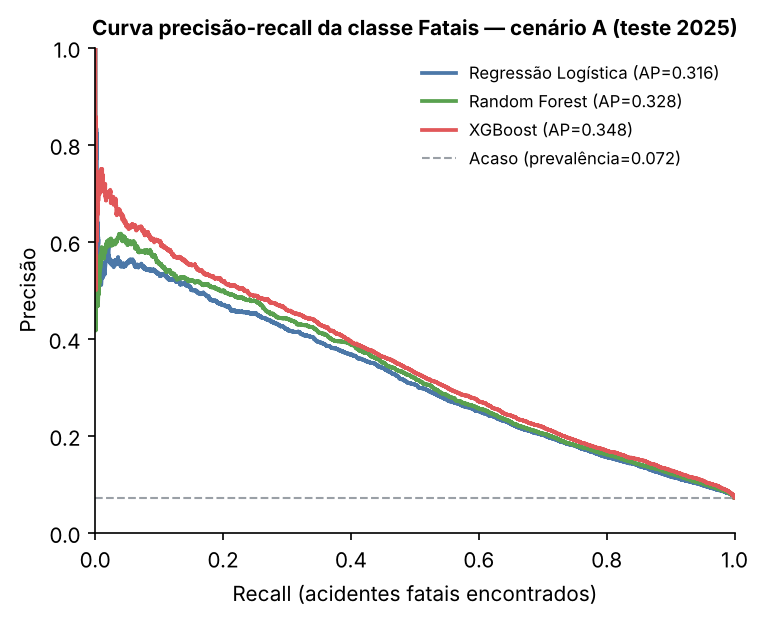

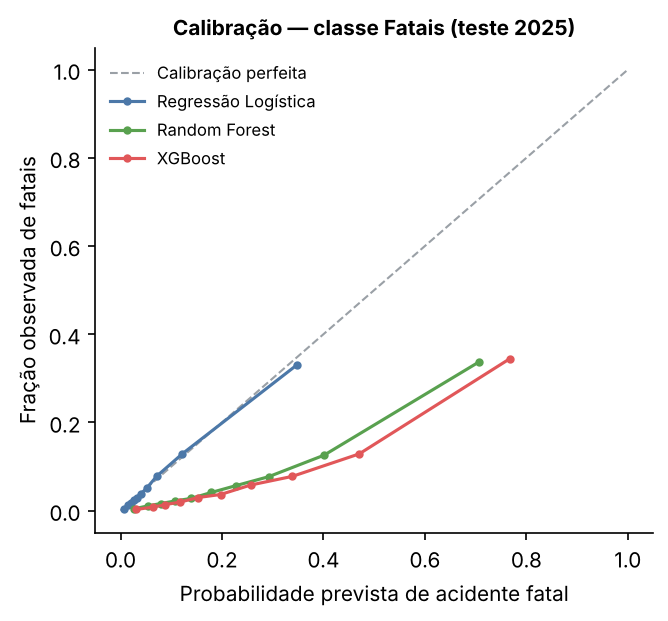

,modelo,pr_auc_fatais,recall_fatais_com_precisao_0.30,precisao_fatais_com_recall_0.50
0,dummy,0.072,0.000,0.072
2,lr,0.316,0.505,0.305
4,rf,0.328,0.527,0.319
6,xgb,0.348,0.549,0.330


In [4]:
display(Image(str(config.FIGURES_DIR / "res_01_curvas_pr_cenario_A.png")))
display(Image(str(config.FIGURES_DIR / "res_03_calibracao_A.png")))
res[res.cenario == "A"][["modelo", "pr_auc_fatais", "recall_fatais_com_precisao_0.30", "precisao_fatais_com_recall_0.50"]].round(3)

## 3. Matriz de confusão do modelo escolhido

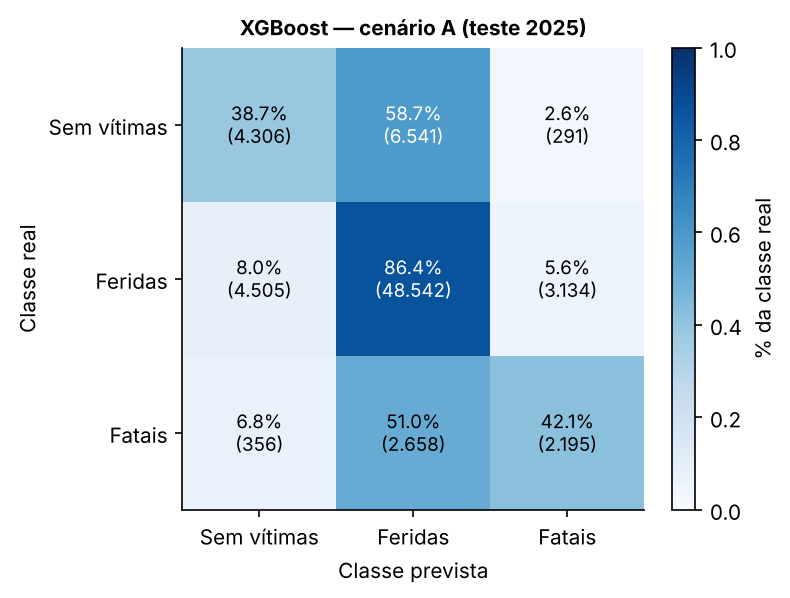

In [5]:
display(Image(str(config.FIGURES_DIR / "res_02_matriz_confusao_melhor_A.png")))

## 4. Vazamento: o que muda com informação pós-acidente e com split aleatório

In [6]:
x = res[res.modelo == "xgb"].set_index("cenario")[["f1_macro", "recall_fatais", "pr_auc_fatais", "roc_auc_macro_ovr"]].round(3)
display(x)
print("Split aleatório:", json.loads((config.TABLES_DIR / "split_aleatorio.json").read_text()))

,f1_macro,recall_fatais,pr_auc_fatais,roc_auc_macro_ovr
cenario,,,,
A,0.561,0.421,0.348,0.780
A_pessoas,0.575,0.429,0.349,0.793
B,0.442,0.290,0.189,0.667
C,0.576,0.433,0.368,0.794


Split aleatório: {'split': 'aleatório estratificado 80/20 (2019-2025)', 'n_teste': 94713, 'f1_macro_argmax': 0.4868875367260462, 'pr_auc_fatais': 0.3357276851476288, 'roc_auc_macro': 0.767222027948924}


## 5. O modelo faz mais do que uma regra simples?

Comparação com a regra "prever Fatal se colisão frontal ou atropelamento de pedestre", na classe Fatais.

In [7]:
pd.DataFrame(json.loads((config.TABLES_DIR / "comparacao_regra_simples.json").read_text())).T.round(3)

,precisao,recall,f1,fatais_reais,previstos_fatais,acertos
regra_frontal_ou_pedestre,0.295,0.441,0.353,5209.0,7795.0,2297.0
modelo,0.391,0.421,0.405,5209.0,5620.0,2195.0
modelo_dentro_frontal_pedestre,0.407,0.850,0.550,2297.0,4801.0,1953.0
modelo_outros_tipos,0.295,0.083,0.130,2912.0,819.0,242.0


O modelo supera a regra em precisão e F1, mas a maior parte dos acertos ainda está nesses dois tipos de acidente. Nos demais tipos, que somam mais da metade dos acidentes fatais, o modelo encontra poucos casos. As variáveis que os distinguiriam (velocidade, tipo de veículo, ocupantes) não estão no cenário A.

## 6. Vieses geográficos e temporais

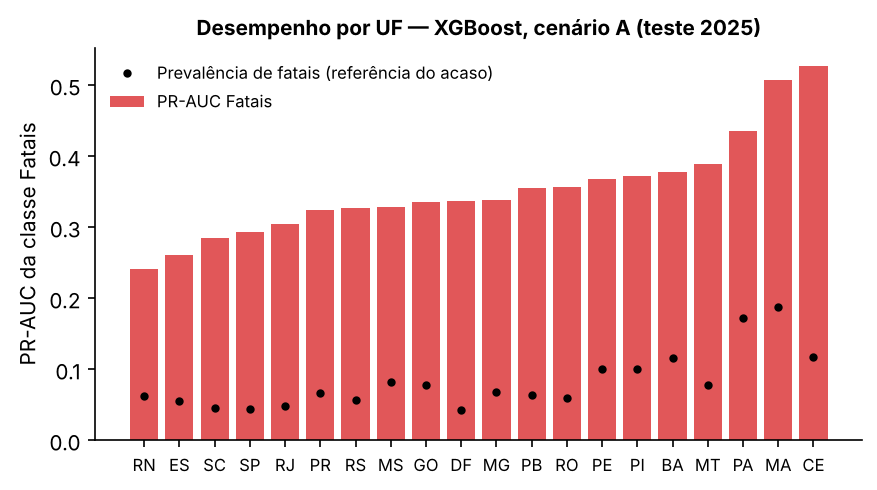

**Por regiao**

,regiao,n,pct_fatais,f1_macro,recall_fatais,precisao_fatais,pr_auc_fatais
0,Sudeste,23323,5.587,0.571,0.360,0.380,0.308
1,Sul,20715,5.600,0.553,0.389,0.378,0.311
2,Nordeste,16018,10.451,0.550,0.480,0.395,0.393
3,Centro-Oeste,8497,7.414,0.557,0.386,0.446,0.347
4,Norte,3975,11.119,0.530,0.516,0.370,0.388


**Por mes**

,mes,n,pct_fatais,f1_macro,recall_fatais,precisao_fatais,pr_auc_fatais
0,1,5527,6.477,0.549,0.402,0.389,0.349
1,2,5287,6.847,0.573,0.412,0.412,0.327
2,3,5960,6.745,0.540,0.353,0.341,0.293
3,4,5786,7.155,0.572,0.442,0.408,0.383
4,5,6096,8.268,0.568,0.429,0.422,0.376
5,6,6122,7.465,0.556,0.446,0.383,0.378
6,7,6238,7.310,0.554,0.412,0.357,0.333
7,8,6246,7.557,0.577,0.443,0.407,0.377
8,9,6017,7.279,0.555,0.409,0.387,0.317
9,10,6252,6.750,0.549,0.419,0.373,0.340


**Por fase_dia**

,fase_dia,n,pct_fatais,f1_macro,recall_fatais,precisao_fatais,pr_auc_fatais
0,Pleno dia,40374,5.073,0.537,0.306,0.375,0.275
1,Plena Noite,24781,10.177,0.559,0.512,0.399,0.396
2,Anoitecer,3926,6.444,0.541,0.399,0.371,0.294
3,Amanhecer,3447,11.198,0.560,0.456,0.404,0.432


**Por tipo_acidente**

,tipo_acidente,n,pct_fatais,f1_macro,recall_fatais,precisao_fatais,pr_auc_fatais
0,Colisão traseira,14360,4.311,0.409,0.132,0.343,0.182
1,Saída de leito carroçável,10209,5.926,0.427,0.063,0.248,0.139
2,Colisão transversal,9306,4.588,0.371,0.082,0.294,0.155
3,Colisão lateral mesmo sentido,7885,2.689,0.390,0.047,0.400,0.132
4,Tombamento,6351,4.220,0.383,0.030,0.258,0.151
5,Colisão com objeto,5109,5.813,0.426,0.098,0.345,0.175
6,Colisão frontal,4738,29.443,0.376,0.871,0.386,0.476
7,Queda de ocupante de veículo,3450,2.522,0.373,0.092,0.348,0.203
8,Atropelamento de Pedestre,3057,29.506,0.424,0.818,0.447,0.557
9,Colisão lateral sentido oposto,2152,9.851,0.398,0.085,0.200,0.172


In [8]:
display(Image(str(config.FIGURES_DIR / "res_05_desempenho_por_uf.png")))
for g in ("regiao", "mes", "fase_dia", "tipo_acidente"):
    display(Markdown(f"**Por {g}**"))
    display(pd.read_csv(config.TABLES_DIR / f"erros_por_{g}.csv").round(3))

## 7. Interpretação: importância por permutação e SHAP

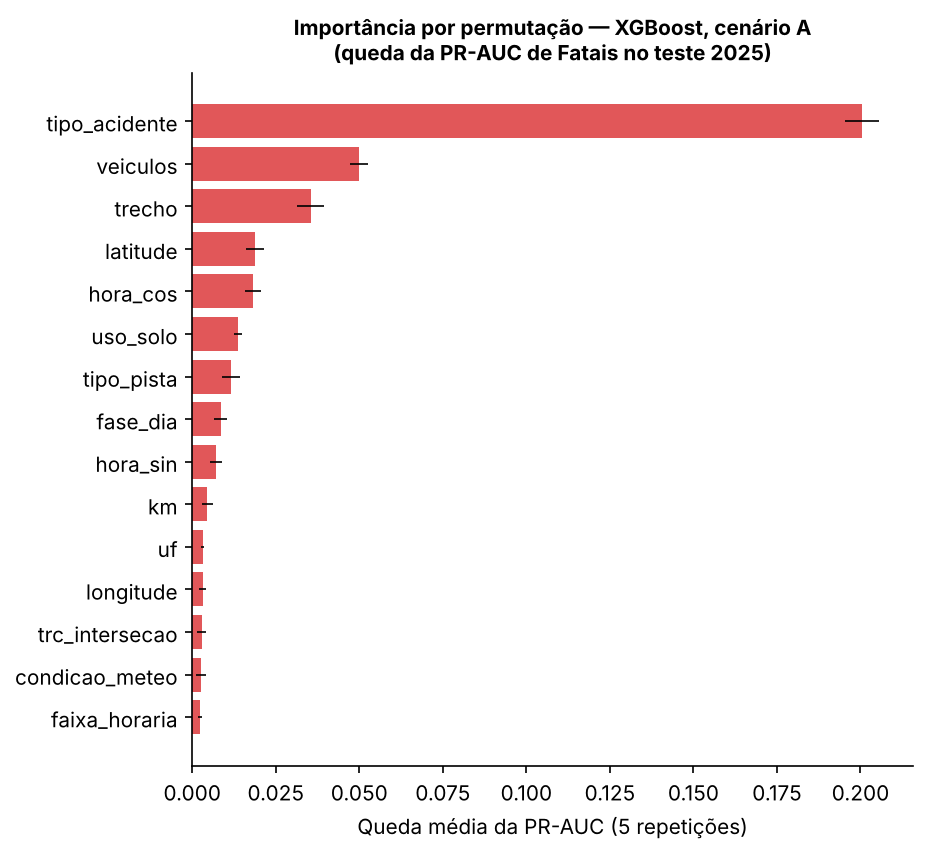

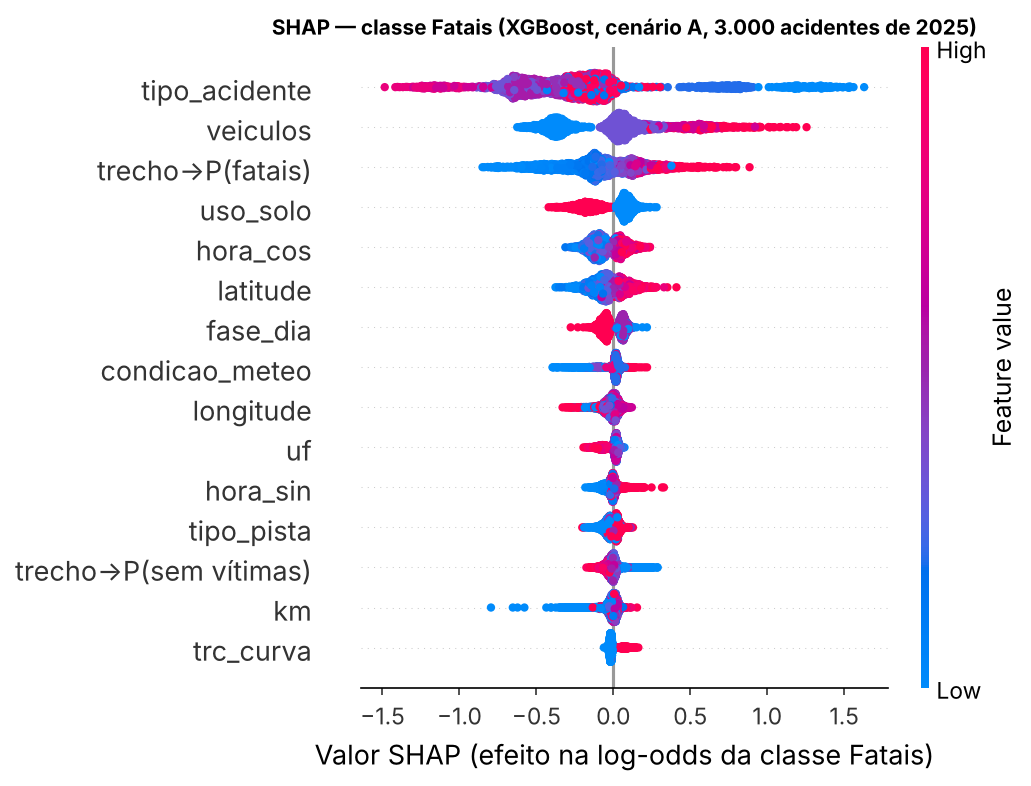

,variavel,media_abs_shap_fatais
0,tipo_acidente,0.4294
1,veiculos,0.2671
2,trecho→P(fatais),0.2090
3,uso_solo,0.1242
4,hora_cos,0.0884
5,latitude,0.0861
6,fase_dia,0.0618
7,condicao_meteo,0.0373
8,longitude,0.0370
9,uf,0.0359


In [9]:
display(Image(str(config.FIGURES_DIR / [f for f in os.listdir(config.FIGURES_DIR) if f.startswith("interp_01")][0])))
display(Image(str(config.FIGURES_DIR / "interp_02_shap_xgb_A.png")))
pd.read_csv(config.TABLES_DIR / "shap_xgb_A.csv").head(15).round(4)

**Como ler:** a importância por permutação mede quanto a PR-AUC de Fatais cai quando uma variável é embaralhada. O SHAP mostra quanto cada variável empurra a probabilidade de acidente fatal para cima ou para baixo em cada acidente. Nos dois casos, a explicação é **do modelo**, não do mundo: uma variável importante é útil para prever, mas isso não prova que ela cause acidentes graves.

As variáveis categóricas estão em codificação ordinal; no gráfico SHAP, a cor delas indica o código da categoria, não uma ordem real de grandeza.

## 8. Conclusões e limitações

As conclusões quantitativas estão no `README.md` e em `reports/resultados.md`, ambos gerados a partir das tabelas deste notebook. Principais limitações:

- a classe Sem Vítimas representa só acidentes atendidos pela PRF (declarações online ficam fora da base);
- o rótulo conta só óbitos no local; mortes posteriores aparecem como feridos;
- o clima e o traçado são anotados pelo policial, e o traçado mudou de padrão em 2022;
- os arquivos usados vieram de cópias públicas dos dados oficiais (`data/README.md`).